# Iris Flower Classification

**Objective:** To build machine learning classification models that predict the species of an iris flower (Setosa, Versicolor, or Virginica) using its sepal and petal measurements.

**Libraries Used:** Python, Pandas, NumPy, Matplotlib, Seaborn and Scikit-learn.

**Models Used:**
- Logistic Regression
- K-Nearest Neighbors (KNN)

In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris

In [2]:
# Load the built-in Iris dataset

iris = load_iris()

# Convert dataset into a DataFrame
df = pd.DataFrame(iris.data, columns=iris.feature_names)

# Add species names
df['species'] = pd.Categorical.from_codes(
    iris.target, iris.target_names
)

# Display first five rows
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## Exploratory Data Analysis (EDA)

In [3]:
df.shape


(150, 5)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   sepal length (cm)  150 non-null    float64 
 1   sepal width (cm)   150 non-null    float64 
 2   petal length (cm)  150 non-null    float64 
 3   petal width (cm)   150 non-null    float64 
 4   species            150 non-null    category
dtypes: category(1), float64(4)
memory usage: 5.1 KB


In [5]:
print(df.isnull().sum())

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64


In [7]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [8]:
print(df['species'].value_counts())

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


## Data Visualisation



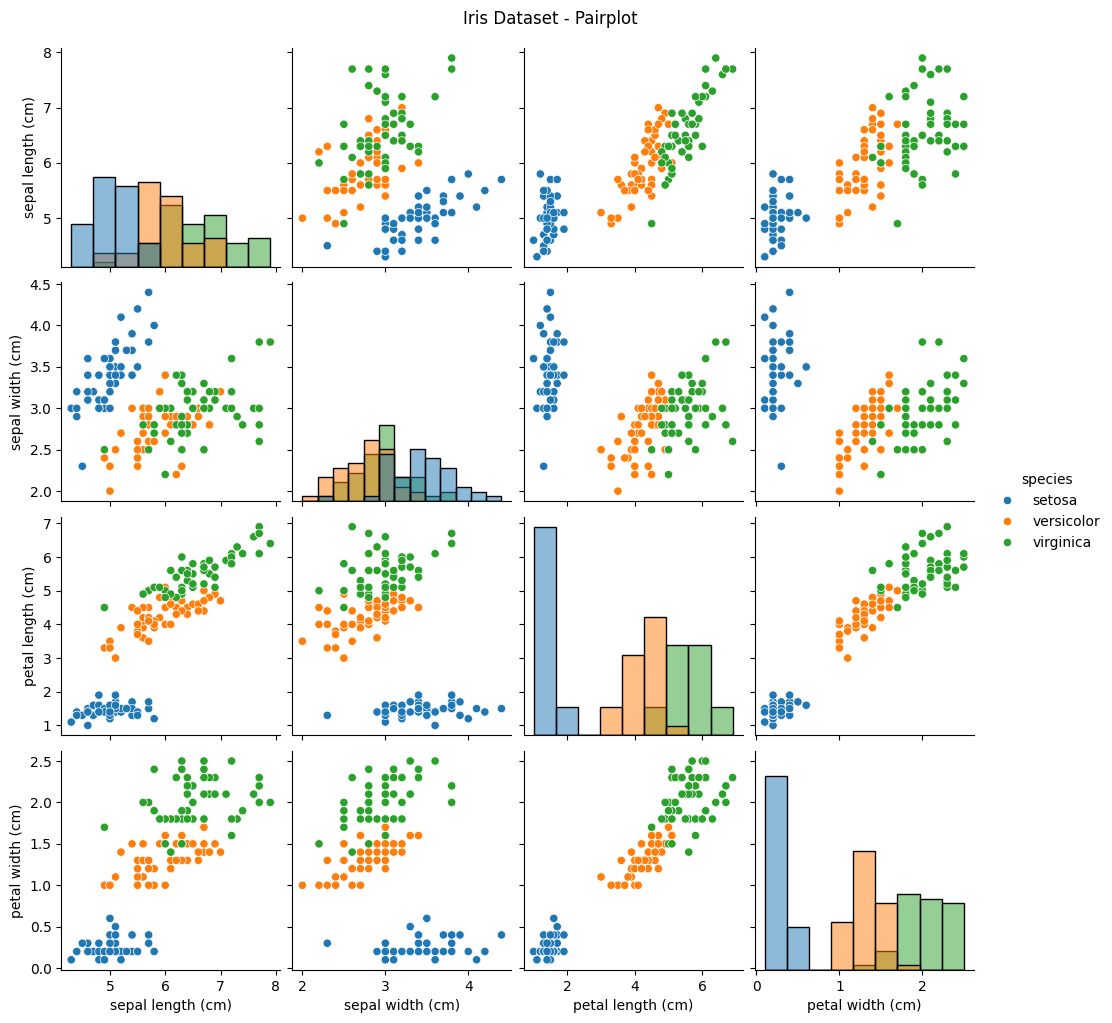

In [9]:
# Visualise relationships between flower measurements

sns.pairplot(
    df,
    hue='species',
    diag_kind='hist'
)

plt.suptitle("Iris Dataset - Pairplot", y=1.02)
plt.show()

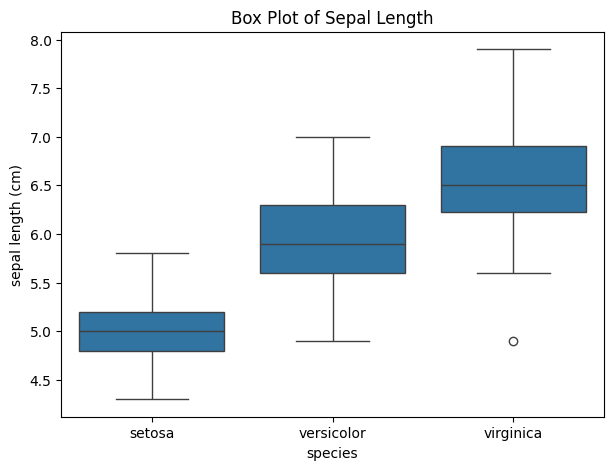

In [11]:
# Sepal length
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x='species', y='sepal length (cm)')
plt.title("Box Plot of Sepal Length")
plt.show()

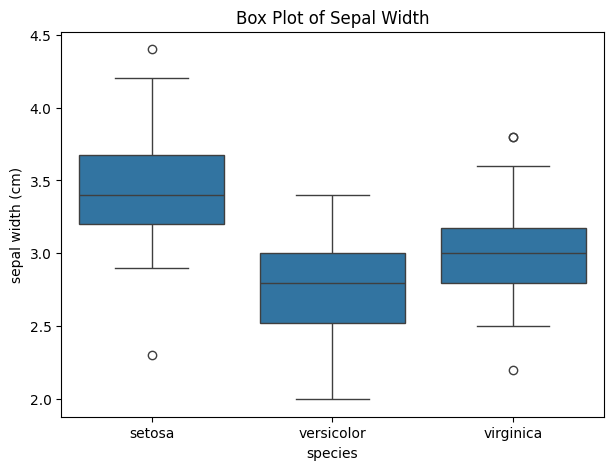

In [12]:
#Sepal Width
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x='species', y='sepal width (cm)')
plt.title("Box Plot of Sepal Width")
plt.show()

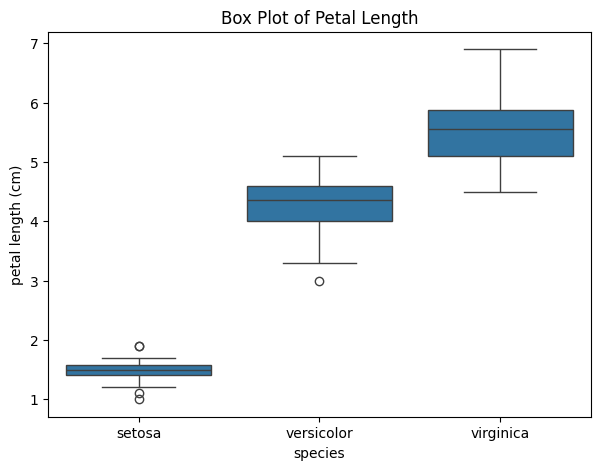

In [13]:
# Petal Length
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x='species', y='petal length (cm)')
plt.title("Box Plot of Petal Length")
plt.show()

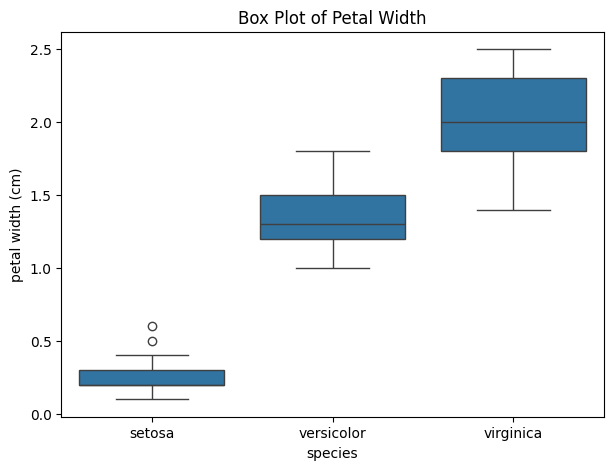

In [14]:
#petal Width
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x='species', y='petal width (cm)')
plt.title("Box Plot of Petal Width")
plt.show()

Observations:
- Setosa is clearly distinguishable from the other two species based on petal measurements.
- Versicolor and Virginica have some overlapping measurements.
- Petal length and petal width appear to be useful features for classification.
- The box plots help compare the distribution and variation of each feature.

## Feature correlation analysis

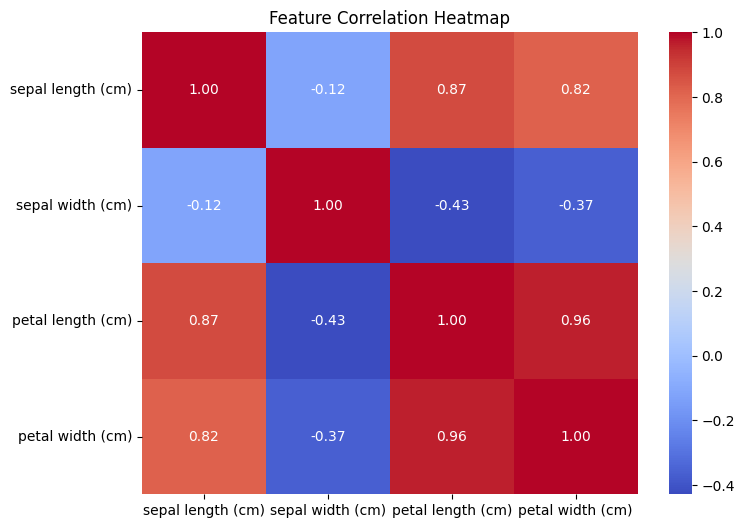

In [15]:
# Calculate correlation between numerical features

correlation = df.iloc[:, :4].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Feature Correlation Heatmap")
plt.show()

Feature Selection Observation:
- Petal length and petal width are highly useful for distinguishing Iris species.
- Setosa is easily distinguishable using petal measurements.
- Sepal measurements show more overlap between species.
- Therefore, petal length and petal width are considered highly discriminative features.

##Train/Test Split
Before training our models, we need to divide our dataset into two parts:
- 80% Training data: Used to teach the model.
- 20% Testing data: Used to check how well the model performs on unseen data.

In [16]:
from sklearn.model_selection import train_test_split

In [17]:
X = df.drop('species', axis=1)
y = df['species']

In [19]:
#Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (120, 4)
Testing data: (30, 4)


##Train Machine Learning Models

In [ ]:
#Logistic Regression

In [20]:
from sklearn.linear_model import LogisticRegression

In [21]:
# Create Logistic Regression model
lr_model = LogisticRegression(max_iter=200)

# Train the model
lr_model.fit(X_train, y_train)

LogisticRegression(max_iter=200)

In [22]:
# Predict flower species
y_pred_lr = lr_model.predict(X_test)

print(y_pred_lr)

['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor' 'virginica' 'virginica'
 'virginica' 'versicolor' 'setosa' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor' 'virginica'
 'virginica' 'virginica' 'versicolor' 'setosa' 'virginica' 'setosa']


In [23]:
from sklearn.metrics import accuracy_score

lr_accuracy = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Accuracy:", lr_accuracy)

Logistic Regression Accuracy: 0.9666666666666667


In [24]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

In [25]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [26]:
knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_scaled, y_train)

KNeighborsClassifier()

In [27]:
y_pred_knn = knn_model.predict(X_test_scaled)

print(y_pred_knn)

['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor' 'virginica' 'virginica'
 'virginica' 'versicolor' 'setosa' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'versicolor' 'setosa' 'virginica' 'versicolor' 'versicolor'
 'virginica' 'versicolor' 'versicolor' 'setosa' 'virginica' 'setosa']


In [28]:
knn_accuracy = accuracy_score(y_test, y_pred_knn)

print("KNN Accuracy:", knn_accuracy)

KNN Accuracy: 0.9333333333333333


## Model Evaluation

In [29]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [30]:
print("Logistic Regression Evaluation")

print("Accuracy:", accuracy_score(y_test, y_pred_lr))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

Logistic Regression Evaluation
Accuracy: 0.9666666666666667

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



In [31]:
print("KNN Evaluation")

print("Accuracy:", accuracy_score(y_test, y_pred_knn))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn))

KNN Evaluation
Accuracy: 0.9333333333333333

Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



## Model Comparison

In [35]:
#model comparison
model_comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'KNN'],
    'Accuracy': [lr_accuracy, knn_accuracy]
})

model_comparison

,Model,Accuracy
0,Logistic Regression,0.966667
1,KNN,0.933333


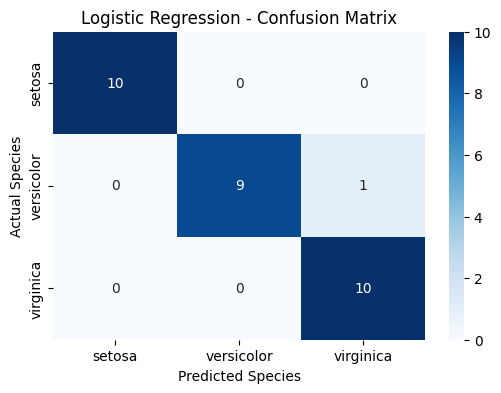

In [36]:
cm_lr = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

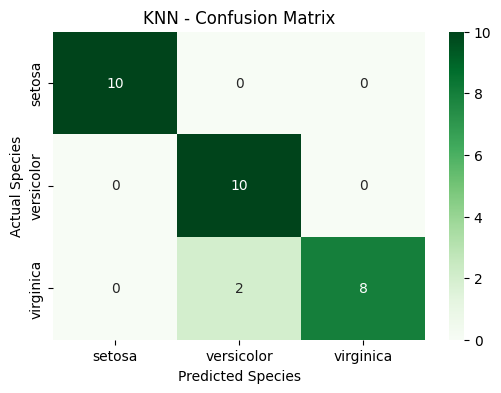

In [37]:
cm_knn = confusion_matrix(y_test, y_pred_knn)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_knn,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.title("KNN - Confusion Matrix")
plt.show()

## Best Performing Model

After comparing Logistic Regression and K-Nearest Neighbors (KNN), Logistic Regression performed better.

- Logistic Regression achieved an accuracy of 96.67%.
- KNN achieved an accuracy of 93.33%.

Therefore, Logistic Regression is selected as the best-performing model because it achieved higher accuracy on the test dataset.

It successfully classified most iris flower samples into their correct species.

## Conclusion

The Iris Flower Classification task was successfully completed using Python and Machine Learning.

Exploratory Data Analysis was performed to understand the dataset, and visualisations were used to identify important features. Two classification models, Logistic Regression and KNN, were trained and evaluated.

Logistic Regression achieved the highest accuracy of 96.67%, making it the best-performing model in this experiment.

The project demonstrates how machine learning can classify iris flower species using their physical measurements.